# Native Model — Slow vs Fast Mask Comparison (QVGA)

For the **native** (pure-NumPy) background-subtraction model run at **QVGA (320x240)** resolution, this notebook shows an `N x 3` image grid per sequence: **original frame**, **slow mask**, **fast mask**, one row per frame. The masks are QVGA; the original frames are shown at their native resolution.

Sequences: **canoe** and **busStation**, at **0.1 fps** (`data_0_1fps`).

| column | source |
| --- | --- |
| original | `data_0_1fps/<seq>/input/in%06d.jpg` |
| slow mask | `results_native_qvga/0_1fps/<seq>/bin%06d.png` |
| fast mask | `results_native_fast_qvga/0_1fps/<seq>/bin%06d.png` |

In [1]:
import re
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

SEQUENCES = ['canoe', 'busStation']
INPUT_ROOT = Path('data_0_1fps')
SLOW_ROOT = Path('results_native_qvga') / '0_1fps'
FAST_ROOT = Path('results_native_fast_qvga') / '0_1fps'
COLUMN_TITLES = ['Original', 'Slow mask (native)', 'Fast mask (native)']


def frame_number(name):
    """Extract the frame number from a mask/frame filename."""
    return int(re.search(r'(\d+)', name).group(1))


def show_grid(sequence):
    """Render the original/slow/fast image grid for one sequence."""
    frames = sorted(
        (INPUT_ROOT / sequence / 'input').glob('*.jpg'),
        key=lambda p: frame_number(p.name),
    )
    rows = len(frames)
    fig, axes = plt.subplots(rows, 3, figsize=(9, 2.6 * rows))
    axes = axes.reshape(rows, 3)
    for row, frame_path in enumerate(frames):
        number = frame_number(frame_path.name)
        original = cv2.cvtColor(cv2.imread(str(frame_path)), cv2.COLOR_BGR2RGB)
        slow = cv2.imread(str(SLOW_ROOT / sequence / f'bin{number:06d}.png'), 0)
        fast = cv2.imread(str(FAST_ROOT / sequence / f'bin{number:06d}.png'), 0)
        axes[row, 0].imshow(original)
        axes[row, 1].imshow(slow, cmap='gray', vmin=0, vmax=255)
        axes[row, 2].imshow(fast, cmap='gray', vmin=0, vmax=255)
        axes[row, 0].set_ylabel(f'frame {number}', fontsize=11)
        for col in range(3):
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(COLUMN_TITLES[col])
    fig.suptitle(f'{sequence} - 0.1 fps - native model', fontsize=14)
    plt.tight_layout()
    plt.show()

## canoe — 0.1 fps

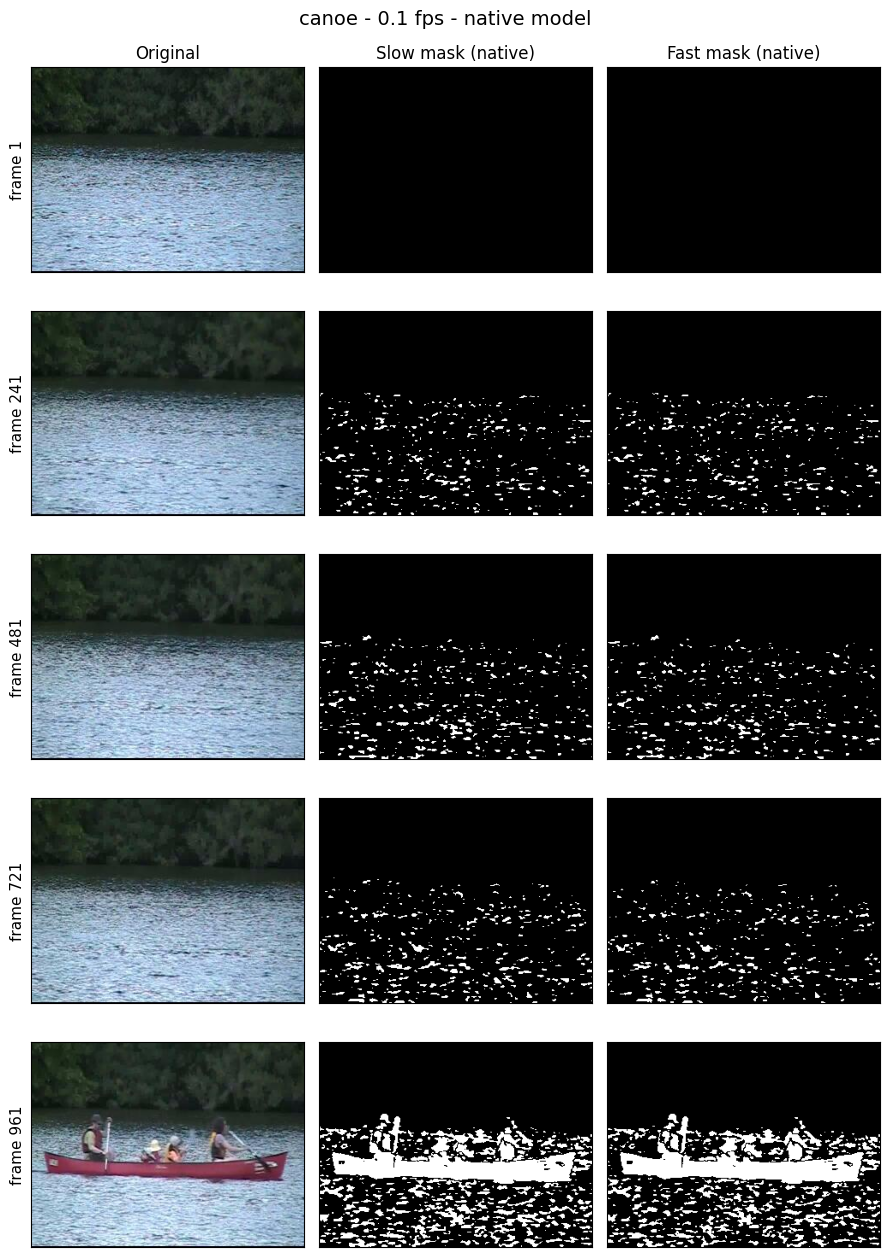

In [2]:
show_grid('canoe')

## busStation — 0.1 fps

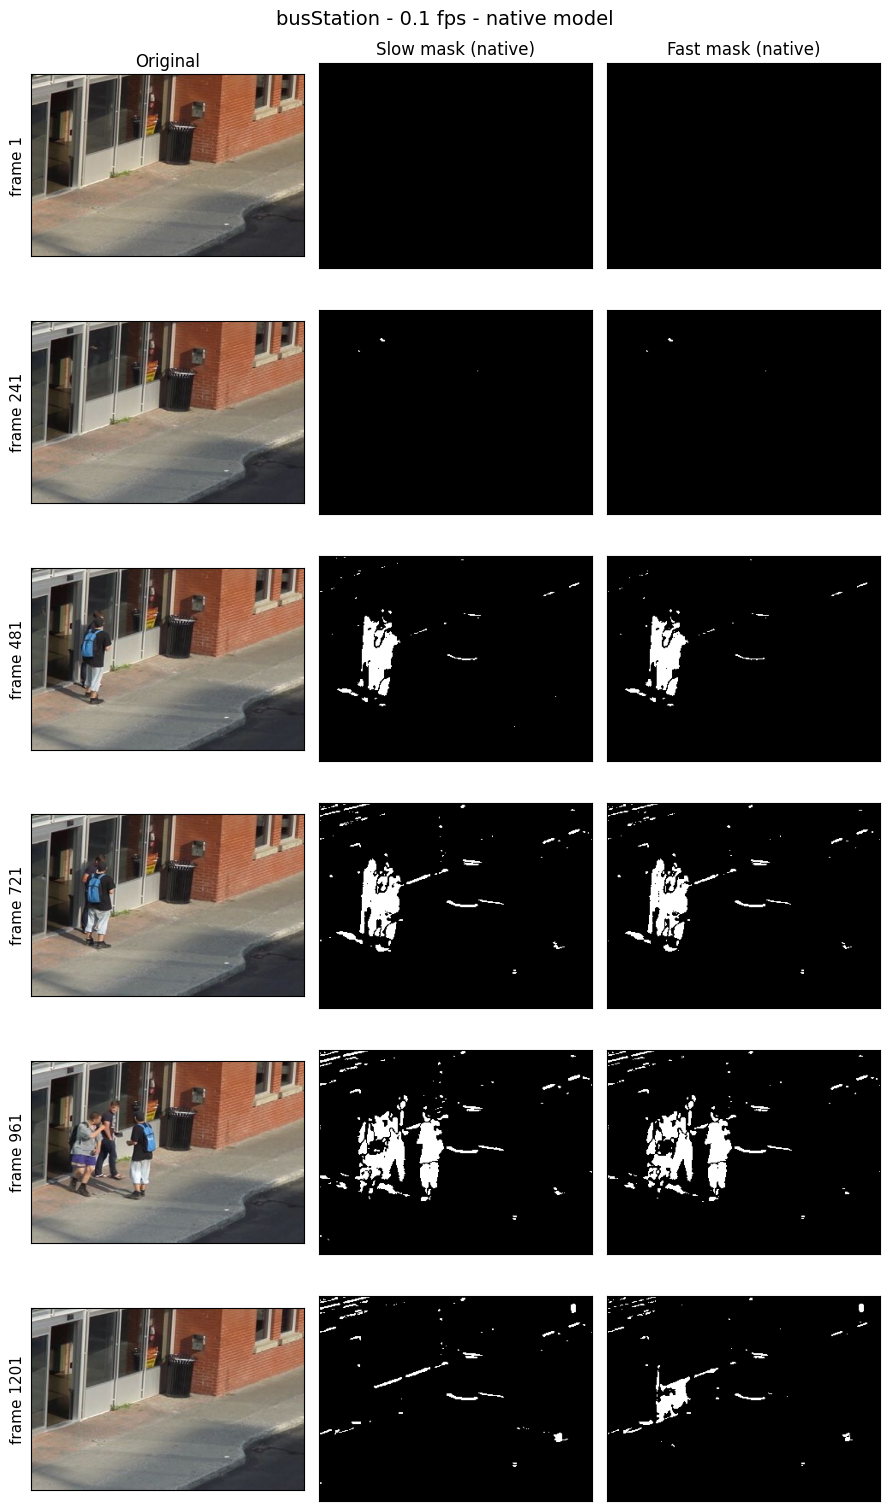

In [3]:
show_grid('busStation')